Experiment with Connected Components

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import io, filters, morphology, measure, img_as_ubyte
from scipy import ndimage as ndi

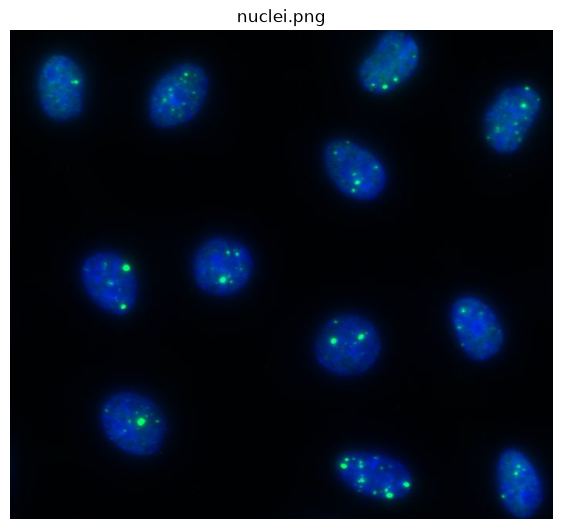

/var/folders/0m/9fw5s1v51f73ynmt361rzw380000gn/T/ipykernel_70063/168384830.py:15: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_objects(mask, min_size=200)   # drop specks/debris
/var/folders/0m/9fw5s1v51f73ynmt361rzw380000gn/T/ipykernel_70063/168384830.py:17: FutureWarning: `binary_opening` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.opening` instead.
  mask = morphology.binary_opening(mask, morphology.disk(3))   # smooth edges


Otsu threshold = 65.4
Number of nuclei = 12


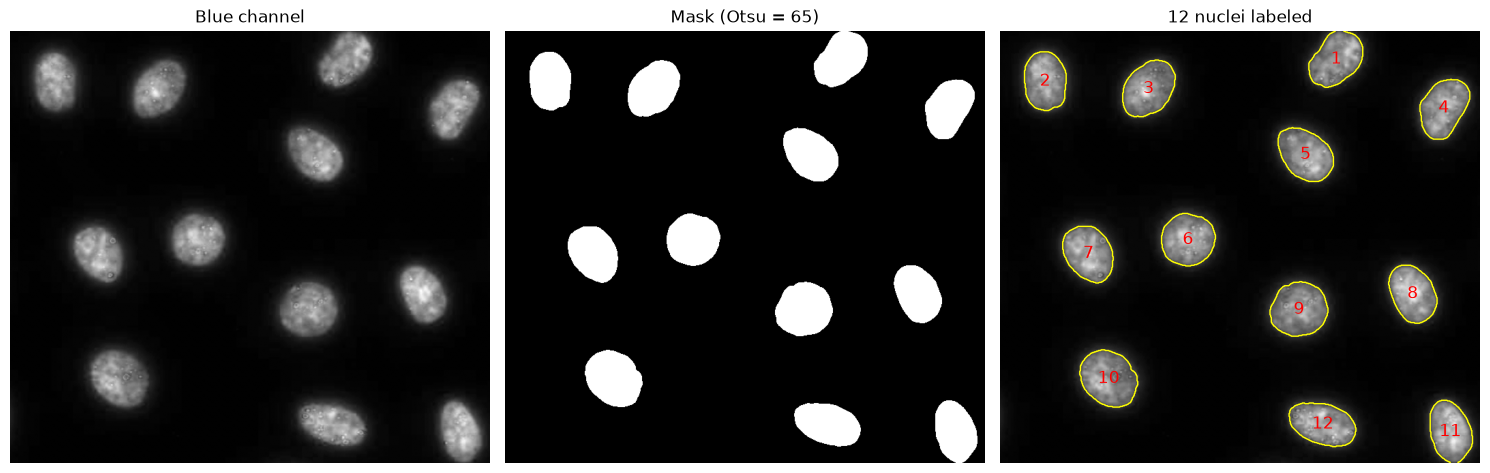

In [4]:
# (a) Read and display 
img = io.imread('nuclei.png')[..., :3]          # drop alpha if present
plt.figure(figsize=(7, 7)); plt.imshow(img); plt.title('nuclei.png'); plt.axis('off'); plt.show()

# (b) Blue channel -> monochrome image, saved to disk
blue  = img[..., 2]
green = img[..., 1]
io.imsave('nuclei_blue.png', blue)               # saved as a grayscale image
io.imsave('nuclei_green.png', green)

# Segment: smooth, Otsu threshold, clean up, label connected components
blue_s = filters.gaussian(blue, sigma=2, preserve_range=True)
t = filters.threshold_otsu(blue_s)
mask = blue_s > t
mask = morphology.remove_small_objects(mask, min_size=200)   # drop specks/debris
mask = ndi.binary_fill_holes(mask)                           # fill holes inside nuclei
mask = morphology.binary_opening(mask, morphology.disk(3))   # smooth edges

labels = measure.label(mask, connectivity=2)
n_nuclei = labels.max()
print(f"Otsu threshold = {t:.1f}")
print(f"Number of nuclei = {n_nuclei}")

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(blue, cmap='gray'); ax[0].set_title('Blue channel')
ax[1].imshow(mask, cmap='gray'); ax[1].set_title(f'Mask (Otsu = {t:.0f})')
ax[2].imshow(blue, cmap='gray')
for r in measure.regionprops(labels):
    y, x = r.centroid
    ax[2].contour(labels == r.label, levels=[0.5], colors='yellow', linewidths=1)
    ax[2].text(x, y, str(r.label), color='red', fontsize=12, ha='center', va='center')
ax[2].set_title(f'{n_nuclei} nuclei labeled')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()

Green spots per nucleus, displayed with cursors (part c)

Top-hat threshold = 44.2, total spots = 50

Nucleus | spots
      1 | 3
      2 | 1
      3 | 6
      4 | 5
      5 | 5
      6 | 4
      7 | 4
      8 | 3
      9 | 3
     10 | 5
     11 | 3
     12 | 8
Total spots assigned: 50


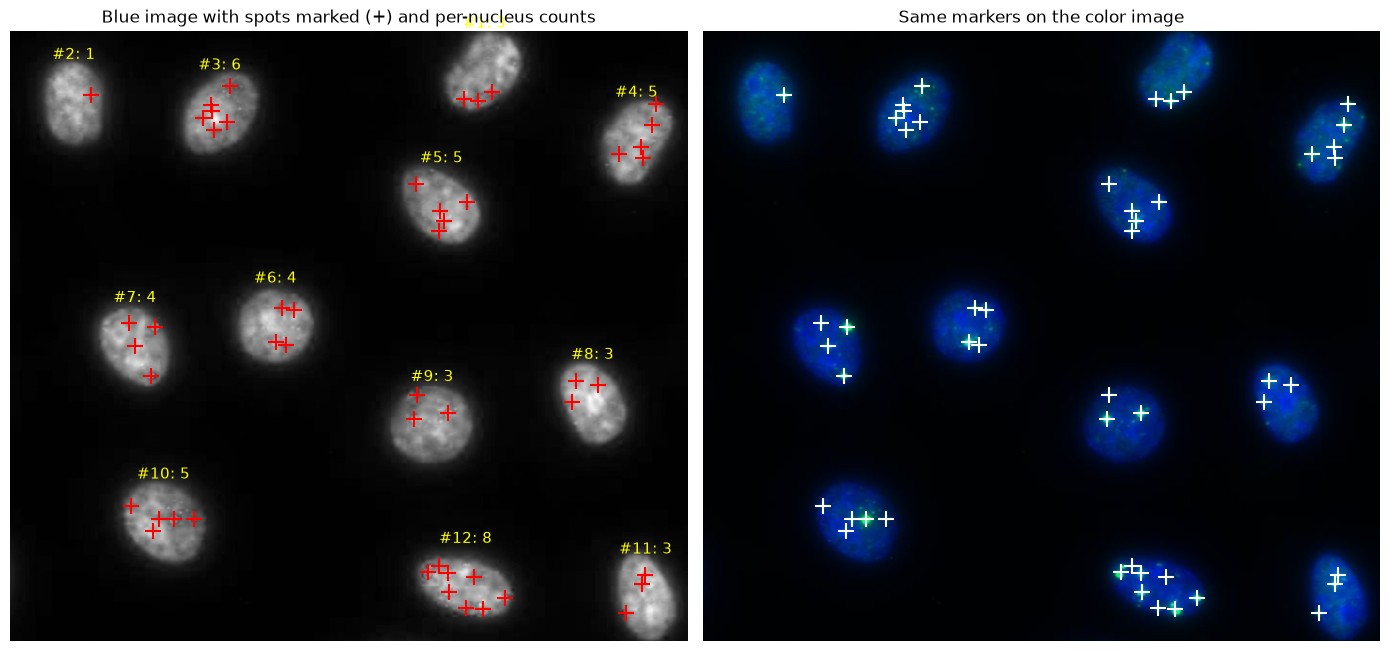

In [7]:
# (c) Spots from the green channel
green_s = filters.gaussian(green, sigma=1, preserve_range=True)

# Remove the slowly varying background so only small bright spots remain (white top-hat)
tophat = morphology.white_tophat(green_s, morphology.disk(7))

# Threshold the top-hat result (Otsu works if spots are clear; raise the factor if you get false spots)
tg = filters.threshold_otsu(tophat)
spot_mask = tophat > tg

# Keep only spots that lie inside a nucleus (slightly dilated so edge spots are not lost)
#nuclei_zone = morphology.binary_dilation(labels > 0, morphology.disk(3))
nuclei_zone = morphology.dilation(labels > 0, morphology.disk(3))

spot_mask &= nuclei_zone
#spot_mask = morphology.remove_small_objects(spot_mask, min_size=3)
spot_mask = morphology.remove_small_objects(spot_mask, max_size=2)

spot_labels = measure.label(spot_mask, connectivity=2)
spots = measure.regionprops(spot_labels)
print(f"Top-hat threshold = {tg:.1f}, total spots = {len(spots)}")

# Assign each spot to a nucleus using the nucleus label under the spot's centroid
counts = {i: 0 for i in range(1, n_nuclei + 1)}
spot_xy = []
for s in spots:
    y, x = s.centroid
    nid = labels[int(round(y)), int(round(x))]
    if nid > 0:
        counts[nid] += 1
        spot_xy.append((x, y))

print("\nNucleus | spots")
for k, v in counts.items():
    print(f"{k:>7} | {v}")
print(f"Total spots assigned: {sum(counts.values())}")

# Display each spot with a cursor (+ marker) on the blue image
fig, ax = plt.subplots(1, 2, figsize=(14, 7))
ax[0].imshow(blue, cmap='gray')
xs, ys = zip(*spot_xy)
ax[0].plot(xs, ys, 'r+', markersize=12, markeredgewidth=1.5)
for r in measure.regionprops(labels):
    y, x = r.centroid
    ax[0].text(x, y - 45, f"#{r.label}: {counts[r.label]}", color='yellow', fontsize=11, ha='center')
ax[0].set_title('Blue image with spots marked (+) and per-nucleus counts')

ax[1].imshow(img)                                  # same markers on the color image
ax[1].plot(xs, ys, 'w+', markersize=12, markeredgewidth=1.5)
ax[1].set_title('Same markers on the color image')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()